In [12]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/loan_default.csv')

print(df.shape)
df.info()
display(df.head(10))


(1012, 18)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1012 entries, 0 to 1011
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   customer_id        1012 non-null   object 
 1   age                1012 non-null   int64  
 2   income             1012 non-null   float64
 3   loan_amount        1012 non-null   float64
 4   credit_score       1012 non-null   float64
 5   employment_years   1012 non-null   float64
 6   debt_to_income     1012 non-null   float64
 7   existing_loans     1012 non-null   int64  
 8   dependents         1012 non-null   int64  
 9   bank_balance       1012 non-null   float64
 10  interest_rate      1012 non-null   float64
 11  employment_type    1012 non-null   object 
 12  marital_status     1012 non-null   object 
 13  education          951 non-null    object 
 14  loan_purpose       1012 non-null   object 
 15  city_tier          1012 non-null   object 
 16  previous_defa

,customer_id,age,income,loan_amount,credit_score,employment_years,debt_to_income,existing_loans,dependents,bank_balance,interest_rate,employment_type,marital_status,education,loan_purpose,city_tier,previous_defaults,loan_default
0,CUST00084,59,52055.0,67855.0,589.0,8.1,0.436,0,4,1841.31,10.75,Contract,Married,High School,Business,Tier 3,2,No
1,CUST00543,58,48605.0,187963.0,641.0,20.4,0.030,0,1,0.00,11.67,Salaried,Single,Graduate,Education,Tier 1,0,No
2,CUST00718,29,54590.0,244551.0,726.0,0.8,0.484,0,0,794.75,8.13,Contract,Married,High School,Personal,Tier 1,1,No
3,CUST00240,56,18951.0,561210.0,726.0,27.0,0.043,0,1,17515.85,8.63,Salaried,Single,High School,Education,Tier 1,0,No
4,CUST00649,37,76183.0,187744.0,658.0,10.1,0.412,1,3,10617.61,8.47,Salaried,Married,Undergraduate,Education,Tier 1,1,No
5,CUST00363,51,43421.0,203423.0,591.0,10.0,0.488,1,0,6242.09,9.82,Salaried,Single,Postgraduate,Education,Tier 1,1,No
6,CUST00302,32,61240.0,219736.0,653.0,7.3,0.460,1,2,564.28,9.22,Contract,Divorced,NaN,Business,Tier 2,1,No
7,CUST00568,43,75088.0,208966.0,635.0,17.5,0.469,0,3,11137.85,9.96,Salaried,Divorced,Undergraduate,Business,Tier 1,1,No
8,CUST00086,43,62544.0,328632.0,640.0,8.0,0.369,0,0,16709.98,9.59,Contract,Married,Graduate,Education,Tier 2,0,No
9,CUST00600,38,54997.0,273677.0,656.0,10.4,0.372,2,3,8650.50,9.71,Salaried,Single,Graduate,Business,Tier 1,0,No


**WRITE DOWN ANSWER:**
The dataset contains 1,012 rows and 18 columns. The numerical columns include age, income, loan_amount, credit_score, employment_years, debt_to_income, existing_loans, dependents, bank_balance, interest_rate, and previous_defaults. The categorical columns are employment_type, marital_status, education, loan_purpose, and city_tier. The customer_id column is used to identify each customer, while loan_default is the target column that tells us whether the customer defaulted or repaid the loan.

               age         income    loan_amount  credit_score  \
count  1012.000000    1012.000000    1012.000000   1012.000000   
mean     42.669960   54157.542490  246006.705534    651.821146   
std      13.986137   21295.031417  116654.104628     79.549937   
min     -52.000000  -74577.000000   20000.000000    411.000000   
25%      32.000000   40859.000000  169464.500000    596.750000   
50%      43.000000   53837.500000  242872.000000    651.500000   
75%      54.000000   68032.750000  324349.500000    705.000000   
max      64.000000  111578.000000  667635.000000    900.000000   

       employment_years  debt_to_income  existing_loans   dependents  \
count       1012.000000     1012.000000     1012.000000  1012.000000   
mean           9.994763        0.368216        0.996047     1.936759   
std            7.718507        0.154261        0.979505     1.390213   
min            0.000000        0.020000        0.000000     0.000000   
25%            3.875000        0.263000      

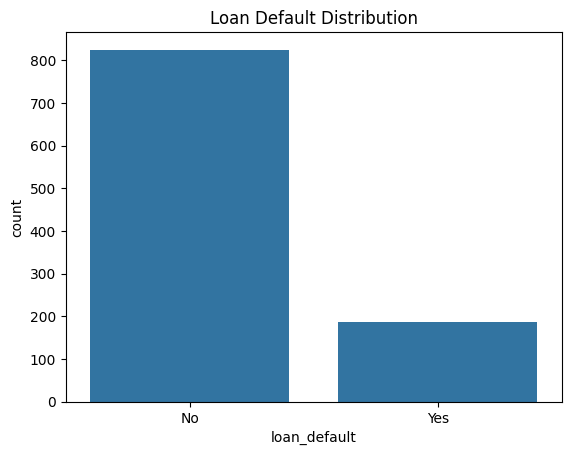

In [13]:

print(df.describe())

for col in df.select_dtypes(include="object").columns:
    print("\n", col)
    print(df[col].value_counts())

import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="loan_default")
plt.title("Loan Default Distribution")
plt.show()


**Write down:**
The target variable is not balanced. Out of 1,012 customers, 825 did not default on their loans, while 187 customers did default. This means that most customers repaid their loans, and fewer customers defaulted. This imbalance matters because a model could achieve high accuracy by predicting the majority class more often, while failing to identify customers who may default. Therefore, we should also evaluate recall, precision, and F1-score.

In [14]:

print("Missing values before cleaning:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

numeric_cols = df.select_dtypes(include="number").columns
print("\nNegative values in numeric columns:")
print((df[numeric_cols] < 0).sum())

categorical_cols = df.select_dtypes(include="object").columns

for col in categorical_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

df = df.drop_duplicates()

print("\nMissing values after cleaning:")
print(df.isnull().sum())

print("\nDataset shape after cleaning:", df.shape)


Missing values before cleaning:
customer_id           0
age                   0
income                0
loan_amount           0
credit_score          0
employment_years      0
debt_to_income        0
existing_loans        0
dependents            0
bank_balance          0
interest_rate         0
employment_type       0
marital_status        0
education            61
loan_purpose          0
city_tier             0
previous_defaults     0
loan_default          0
dtype: int64

Duplicate rows: 11

Negative values in numeric columns:
age                  5
income               5
loan_amount          0
credit_score         0
employment_years     0
debt_to_income       0
existing_loans       0
dependents           0
bank_balance         0
interest_rate        0
previous_defaults    0
dtype: int64

Missing values after cleaning:
customer_id          0
age                  0
income               0
loan_amount          0
credit_score         0
employment_years     0
debt_to_income       0
existin

**Write down:**
The `education` column had 61 missing values, so I filled them using the most frequent value in that column. I found 11 duplicate rows and removed them to avoid repeated records. I also found 5 negative values in `age` and 5 in `income`. These values may be incorrect because age and income should not be negative, so they need further checking before modelling. Cleaning the data helps improve the reliability of the model.

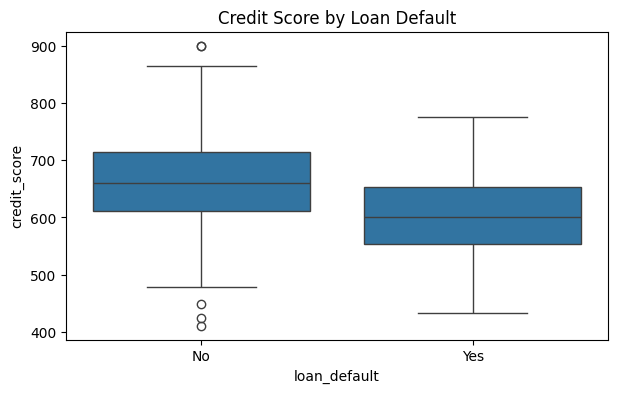

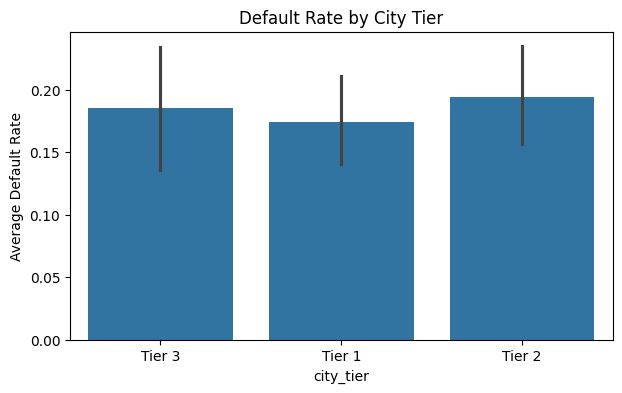

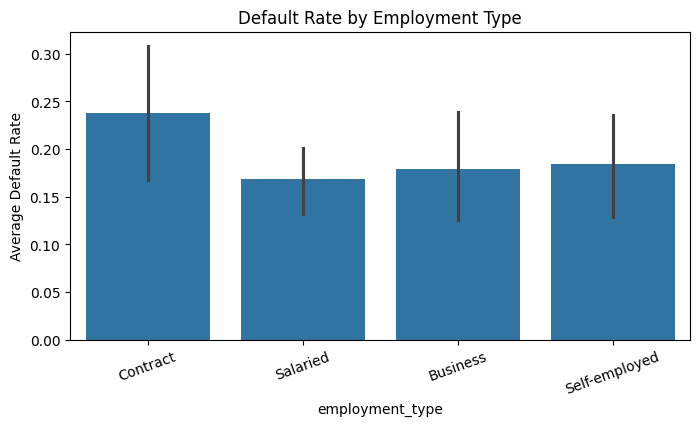

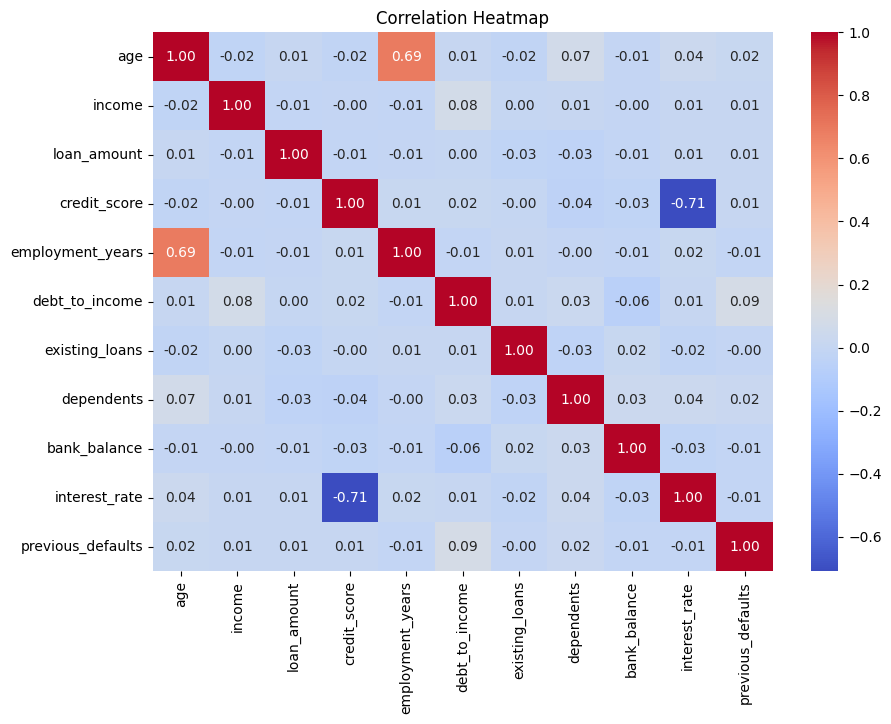

In [15]:

plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="loan_default", y="credit_score")
plt.title("Credit Score by Loan Default")
plt.show()

plt.figure(figsize=(7, 4))
sns.barplot(data=df, x="city_tier", y=df["loan_default"].map({"Yes": 1, "No": 0}))
plt.title("Default Rate by City Tier")
plt.ylabel("Average Default Rate")
plt.show()

plt.figure(figsize=(8, 4))
sns.barplot(data=df, x="employment_type", y=df["loan_default"].map({"Yes": 1, "No": 0}))
plt.title("Default Rate by Employment Type")
plt.ylabel("Average Default Rate")
plt.xticks(rotation=20)
plt.show()

plt.figure(figsize=(10, 7))
sns.heatmap(df.select_dtypes(include="number").corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()


**Write down:**
Credit score appears to be one of the most useful features for distinguishing defaulters from non-defaulters because customers who defaulted generally had lower credit scores. Employment type also shows differences in default rates, with Contract workers having a relatively higher rate and Salaried workers a lower rate. These plots suggest that credit score and employment type may help predict loan default.

In [16]:

df = df.drop(columns=["customer_id"])

df["loan_default"] = df["loan_default"].map({"Yes": 1, "No": 0})

df = pd.get_dummies(df, drop_first=True, dtype=int)

X = df.drop("loan_default", axis=1)
y = df["loan_default"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nFeature columns:")
print(X.columns.tolist())
print("\nTarget values:")
print(y.value_counts())


Features shape: (1001, 24)
Target shape: (1001,)

Feature columns:
['age', 'income', 'loan_amount', 'credit_score', 'employment_years', 'debt_to_income', 'existing_loans', 'dependents', 'bank_balance', 'interest_rate', 'previous_defaults', 'employment_type_Contract', 'employment_type_Salaried', 'employment_type_Self-employed', 'marital_status_Married', 'marital_status_Single', 'education_High School', 'education_Postgraduate', 'education_Undergraduate', 'loan_purpose_Education', 'loan_purpose_Home', 'loan_purpose_Personal', 'city_tier_Tier 2', 'city_tier_Tier 3']

Target values:
loan_default
0    817
1    184
Name: count, dtype: int64


**Write down:**
A Decision Tree in scikit-learn cannot directly use text columns because it requires numerical input. I converted the categorical columns into numerical dummy variables using `pd.get_dummies()`. I also converted the target column so that Yes is represented by 1 and No by 0, and removed `customer_id` because it is only an identifier.

In [17]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)


Training features: (800, 24)
Testing features: (201, 24)
Training target: (800,)
Testing target: (201,)


**Write down:**
I kept 80% of the data for training and 20% for testing. The training set is used to teach the model, while the test set checks how well it predicts data it has not seen before. We keep the test set separate to get a fair evaluation and avoid misleading results.

In [18]:

from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)

train_accuracy = dt.score(X_train, y_train)
test_accuracy = dt.score(X_test, y_test)

print("Training Accuracy:", train_accuracy)
print("Testing Accuracy:", test_accuracy)


Training Accuracy: 1.0
Testing Accuracy: 0.7611940298507462


**Write down:**
The training accuracy is 100%, while the test accuracy is approximately 76.12%. There is a noticeable gap between the two scores, which suggests that the Decision Tree is overfitting the training data. It has learned the training examples very well but does not perform as accurately on unseen data. We can try tuning the tree's parameters to improve its ability to generalise.

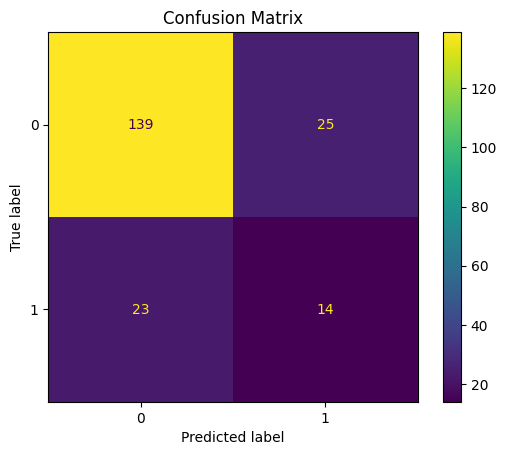

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.85      0.85       164
           1       0.36      0.38      0.37        37

    accuracy                           0.76       201
   macro avg       0.61      0.61      0.61       201
weighted avg       0.77      0.76      0.76       201

ROC-AUC Score: 0.6129696769940673


In [19]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import classification_report, roc_auc_score

y_pred = dt.predict(X_test)
y_prob = dt.predict_proba(X_test)[:, 1]

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(confusion_matrix=cm).plot()
plt.title("Confusion Matrix")
plt.show()

print("Classification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("ROC-AUC Score:", roc_auc_score(y_test, y_prob))


**Write down:**
Approving a loan to a customer who later defaults can cause financial losses for the bank, while rejecting a good customer can mean losing business. In the confusion matrix, the model correctly identified 14 out of 37 defaulters, giving a recall of about 0.38 for the default class. The ROC-AUC score is approximately 0.61, which indicates limited ability to distinguish between defaulters and non-defaulters. Therefore, recall for the default class is important, along with precision and the financial cost of each type of mistake.

In [20]:

from sklearn.model_selection import GridSearchCV

for depth in [3, 5, 7, 10]:
    model = DecisionTreeClassifier(max_depth=depth, random_state=42)
    model.fit(X_train, y_train)
    print(
        "Depth:", depth,
        "| Training accuracy:", round(model.score(X_train, y_train), 3),
        "| Testing accuracy:", round(model.score(X_test, y_test), 3)
    )

param_grid = {
    "max_depth": [3, 5, 7, 10, None],
    "min_samples_leaf": [1, 2, 5, 10],
    "criterion": ["gini", "entropy"]
}

grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

grid.fit(X_train, y_train)

best = grid.best_estimator_
best_pred = best.predict(X_test)
best_prob = best.predict_proba(X_test)[:, 1]

print("\nBest parameters:", grid.best_params_)
print("Best cross-validation F1:", round(grid.best_score_, 3))
print("Tuned test accuracy:", round(best.score(X_test, y_test), 3))
print("Tuned test ROC-AUC:", round(roc_auc_score(y_test, best_prob), 3))
print(classification_report(y_test, best_pred, zero_division=0))


Depth: 3 | Training accuracy: 0.844 | Testing accuracy: 0.821
Depth: 5 | Training accuracy: 0.869 | Testing accuracy: 0.826
Depth: 7 | Training accuracy: 0.905 | Testing accuracy: 0.806
Depth: 10 | Training accuracy: 0.963 | Testing accuracy: 0.801

Best parameters: {'criterion': 'gini', 'max_depth': 7, 'min_samples_leaf': 1}
Best cross-validation F1: 0.306
Tuned test accuracy: 0.806
Tuned test ROC-AUC: 0.593
              precision    recall  f1-score   support

           0       0.84      0.94      0.89       164
           1       0.44      0.22      0.29        37

    accuracy                           0.81       201
   macro avg       0.64      0.58      0.59       201
weighted avg       0.77      0.81      0.78       201



**Write down:**

Among the four tested depths, max_depth = 5 gave the best test accuracy of 82.6%. GridSearchCV selected max_depth = 7, min_samples_leaf = 1, and the gini criterion, with a cross-validation F1-score of 0.306. The tuned model achieved 80.6% test accuracy and a ROC-AUC score of 0.593. Compared with the original tree, tuning reduced overfitting, but the tuned model still has low recall for defaulters at 0.22, so it misses many customers who default.

In [21]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, recall_score, f1_score, roc_auc_score
import pandas as pd

lr = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)

lr.fit(X_train, y_train)

models = {
    "Logistic Regression": lr,
    "Untuned Decision Tree": dt,
    "Tuned Decision Tree": best
}

results = []

for name, model in models.items():
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-score": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, prob)
    })

results_df = pd.DataFrame(results)
print(results_df.round(3))


                   Model  Accuracy  Recall  F1-score  ROC-AUC
0    Logistic Regression     0.836   0.270     0.377    0.760
1  Untuned Decision Tree     0.761   0.378     0.368    0.613
2    Tuned Decision Tree     0.806   0.216     0.291    0.593


**Write down:**

I would recommend Logistic Regression based on these results because it has the highest accuracy of 83.6%, F1-score of 0.377, and ROC-AUC of 0.760. This suggests that it performs better overall than the two Decision Tree models. However, the untuned Decision Tree has a higher recall of 0.378 for defaulters, compared with 0.270 for Logistic Regression. Since identifying customers who may default is important for a bank, the final model should be chosen by considering both predictive performance and the cost of missed defaults.

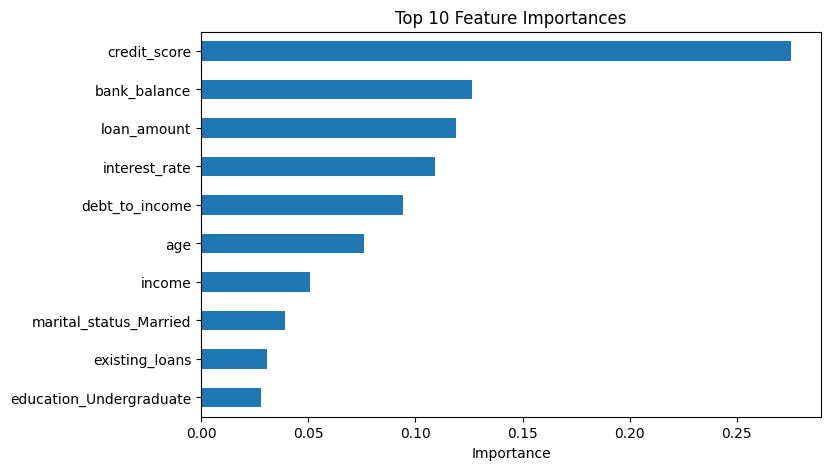

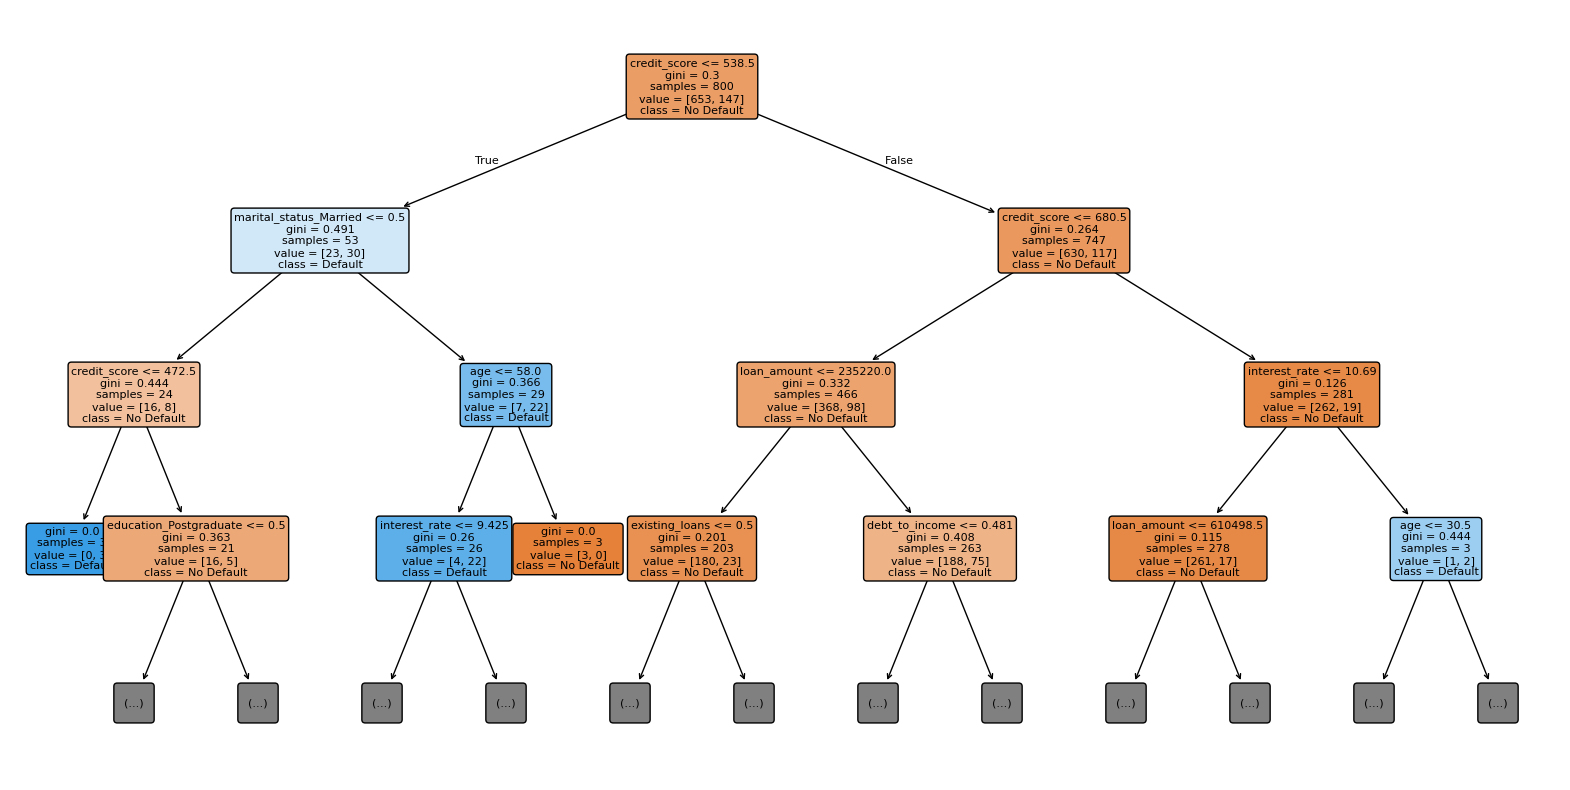

In [22]:

from sklearn.tree import plot_tree

importances = pd.Series(
    best.feature_importances_,
    index=X.columns
).nlargest(10).sort_values()

importances.plot(kind="barh", figsize=(8, 5))
plt.title("Top 10 Feature Importances")
plt.xlabel("Importance")
plt.show()

plt.figure(figsize=(20, 10))
plot_tree(
    best,
    feature_names=X.columns,
    class_names=["No Default", "Default"],
    max_depth=3,
    filled=True,
    rounded=True,
    fontsize=8
)
plt.show()


**Write down:**

The top five most important features are credit score, bank balance, loan amount, interest rate, and debt-to-income ratio. These results partly match the earlier plots because credit score appeared to distinguish defaulters from non-defaulters. One decision rule is that customers with a credit score of 538.5 or below are further classified using marital status and other features. Another rule is that customers with a credit score above 538.5 are evaluated using further credit score, loan amount, and interest rate conditions. These rules show how the model uses different customer details to predict loan default.

**Conclusion:**

In this assignment, I built and evaluated Decision Tree and Logistic Regression models to predict loan defaults. The original Decision Tree achieved 76.1% test accuracy, while Logistic Regression achieved 83.6% accuracy and a ROC-AUC score of 0.760. The tuned Decision Tree reduced overfitting but had low recall for defaulters, meaning it missed many customers who might default. The models help identify patterns in customer data, but their predictions are not always correct. I would improve the project by testing a Random Forest model and focusing on improving recall for the default class.